# Практическая работа №3. Свёрточные нейронные сети

**Работу выполнил (а):**

ФИО, ИТМО ID

Лесюков Глеб Вадимович, 489577

# Классификация цветов с помощью свёрточных нейронных сетей.


В работе необходимо познакомится с различными архитектурами сверхточных нейронных сетей и их обучением на GPU (англ. graphics processing, графический процессор) на языке программирования Python 3 и фреймворка Torch (PyTorch).  Для этого предлагается использовать ресурсы Google Colab - Colaboratory, для выполнения вычислений на GPU. После с ознакомления, выполнить практическое задане в конце данной тетради (notebook).

Рассмотрим [Датасет](https://www.kaggle.com/alxmamaev/flowers-recognition ) содержащий 4242 изображения цветов размеченных по 5 видам (тюльпан, ромашка, подсолнух, роза, одуванчик). Данный набор данных можно скачать по [ссылке](https://www.kaggle.com/alxmamaev/flowers-recognition ) с сайте kaggle.

Загрузите папку с картинками на гугл диск, чтобы не загружать ее каждый раз заново при перезапуске колаба. Структура файлов (можно посмотреть в меню слева) может быть такой: "/content/drive/My Drive/data/flowers".

Обязательно подключите аппаратный ускоритель (GPU) к среде выполнения. В меню сверху: Среда выполнения -> Сменить среду выполнения

Первым делом разберите более детально код выполнив код ниже.

# Подготовка

Загружаем библиотеки. Фиксируем random.seed для воспроизводимости

In [1]:
import numpy as np
import os
import torch
import torchvision
from torchvision.datasets.utils import download_url
from torch.utils.data import random_split
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torchvision.transforms import ToTensor
from torch.utils.data.dataloader import DataLoader
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import random
from tqdm import tqdm
import matplotlib.pyplot as plt

random.seed(0)
torch.manual_seed(0)

Выбираем на чем будем делать вычисления - CPU или GPU (cuda)

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


Блок для соединения с Google Colab

In [3]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

FOLDERNAME = 'data/flowers'

assert FOLDERNAME is not None, "[!] Enter the foldername."

%cd drive/My\ Drive
#%cp -r $FOLDERNAME ../../
#%cd ../../
%cd data/flowers/
#!bash get_datasets.sh
#%cd ../../

#+For kaggle______________________________________________
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))
# FOLDERNAME = '/kaggle/input/flowers-recognition/flowers'
# %cd /kaggle/input/flowers-recognition/flowers

Mounted at /content/drive
/content/drive/My Drive
/content/drive/My Drive/data/flowers


In [4]:
prepare_imgs = torchvision.transforms.Compose(
    [
        torchvision.transforms.Resize((224, 224)), #приводим картинки к одному размеру
        torchvision.transforms.ToTensor(), # упаковывем их в тензор
        torchvision.transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225] # нормализуем картинки по каналам
        ),
    ]
)
# задаем датасет. Лейблы - имена папок:
dataset = ImageFolder('/content/drive/My Drive/data/flowers', transform=prepare_imgs)

In [5]:
dataset.imgs[2]

('/content/drive/My Drive/data/flowers/daisy/10172379554_b296050f82_n.jpg', 0)

In [6]:
class ValueMeter(object):
  """
  Вспомогательный класс, чтобы отслеживать loss и метрику
  """
  def __init__(self):
      self.sum = 0
      self.total = 0

  def add(self, value, n):
      self.sum += value*n
      self.total += n

  def value(self):
      return self.sum/self.total

def log(mode, epoch, loss_meter, accuracy_meter, best_perf=None):
  """
  Вспомогательная функция, чтобы
  """
  print(
      f"[{mode}] Epoch: {epoch:0.2f}. "
      f"Loss: {loss_meter.value():.2f}. "
      f"Accuracy: {100*accuracy_meter.value():.2f}% ", end="\n")

  if best_perf:
      print(f"[best: {best_perf:0.2f}]%", end="")


# Сверточная нейросеть с нуля

## Вручную прописываем слои

In [7]:
model = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Flatten(),
            nn.Linear(256*28*28, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 5))
model.to(device) # отправляем модель на девайс (GPU)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU()
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU()
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU()
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU()
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (15): Flatten(start_dim=1, end_dim=-1)
  (16): Linear(in_features=200704, out_features=1024, bias=True)
  (17): ReLU()
  (18): Linear(in_features=1024, out_features=512, bias=True)
  (19): ReLU()
  (20): Lin

Задаем гиперпараметры для обучения:

# Задаем параметры и функцию для обучения. Разбиваем датасет на train/validation

In [8]:
batch_size = 32
optimizer = torch.optim.Adam(params = model.parameters())
lr = 0.001

Разбиваем датасет на train и validation

Задаем dataloader'ы - объекты для итеративной загрузки данных и лейблов для обучения и валидации

In [9]:
train_set, val_set = torch.utils.data.random_split(dataset, [len(dataset)-1000, 1000])
print('Размер обучающего и валидационного датасета: ', len(train_set), len(val_set))
loaders = {'training': DataLoader(train_set, batch_size, pin_memory=True,num_workers=2, shuffle=True),
           'validation':DataLoader(val_set, batch_size, pin_memory=True,num_workers=2, shuffle=False)}

Размер обучающего и валидационного датасета:  3317 1000


Функция для подсчета Accuracy

In [10]:
def accuracy(outputs, labels):
    _, preds = torch.max(outputs, dim=1)
    return torch.tensor(torch.sum(preds == labels).item() / len(preds))

Функция для обучения и валидации модели

In [ ]:
def trainval(model, loaders, optimizer, epochs=10):
    """
    model: модель, которую собираемся обучать
    loaders: dict с dataloader'ами для обучения и валидации
    """
    loss_meter = {'training': ValueMeter(), 'validation': ValueMeter()}
    accuracy_meter = {'training': ValueMeter(), 'validation': ValueMeter()}

    loss_track = {'training': [], 'validation': []}
    accuracy_track = {'training': [], 'validation': []}

    for epoch in range(epochs): # итерации по эпохам
        for mode in ['training', 'validation']: # обучение - валидация
            # считаем градиаент только при обучении:
            with torch.set_grad_enabled(mode == 'training'):
                # в зависимоти от фазы переводим модель в нужный ружим:
                model.train() if mode == 'training' else model.eval()
                for imgs, labels in tqdm(loaders[mode]): 
                    imgs = imgs.to(device) # отправляем тензор на GPU
                    labels = labels.to(device)
                    bs = labels.shape[0]  # размер батча (отличается для последнего батча в лоадере)

                    preds = model(imgs) # forward pass - прогоняем тензор с картинками через модель
                    loss = F.cross_entropy(preds, labels) # считаем функцию потерь
                    acc = accuracy(preds, labels) # считаем метрику

                    # храним loss и accuracy для батча
                    loss_meter[mode].add(loss.item(), bs)
                    accuracy_meter[mode].add(acc, bs)

                    # если мы в фазе обучения
                    if mode == 'training':
                        optimizer.zero_grad() # обнуляем прошлый градиент
                        loss.backward() # делаем backward pass (считаем градиент)
                        optimizer.step() # обновляем веса
            # в конце фазы выводим значения loss и accuracy
            log(mode, epoch, loss_meter[mode], accuracy_meter[mode])

            # сохраняем результаты по всем эпохам
            loss_track[mode].append(loss_meter[mode].value())
            accuracy_track[mode].append(accuracy_meter[mode].value())
    return loss_track, accuracy_track

# Обучаем базовую модель

Проверим загрузку видеокарты, прежде чем запустить обучение:

Запускаем обучение на 10 эпох

In [12]:
loss_track, accuracy_track = trainval(model, loaders, optimizer, epochs=10)

100%|██████████| 104/104 [06:47<00:00,  3.92s/it]


[training] Epoch: 0.00. Loss: 1.41. Accuracy: 36.54% 


100%|██████████| 32/32 [02:02<00:00,  3.83s/it]


[validation] Epoch: 0.00. Loss: 1.52. Accuracy: 36.70% 


100%|██████████| 104/104 [00:36<00:00,  2.83it/s]


[training] Epoch: 1.00. Loss: 1.34. Accuracy: 40.65% 


... (30 outputs left out)

100%|██████████| 104/104 [00:34<00:00,  3.02it/s]


[training] Epoch: 9.00. Loss: 0.68. Accuracy: 72.40% 


100%|██████████| 32/32 [00:06<00:00,  4.67it/s]

[validation] Epoch: 9.00. Loss: 1.87. Accuracy: 53.51% 


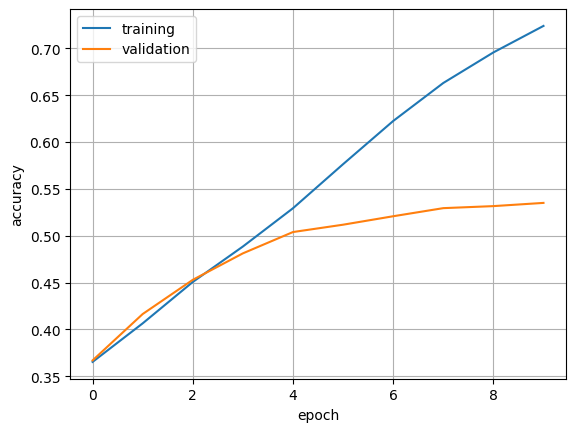

In [13]:
from matplotlib import pyplot as plt
%matplotlib inline
plt.plot(accuracy_track['training'], label='training')
plt.plot(accuracy_track['validation'], label='validation')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.grid()
plt.legend()

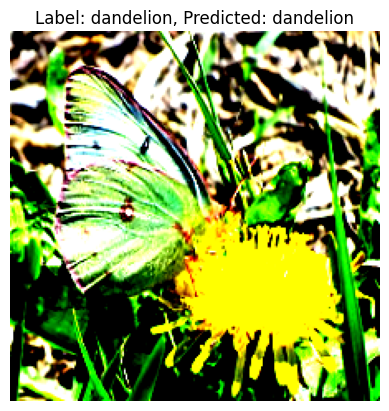

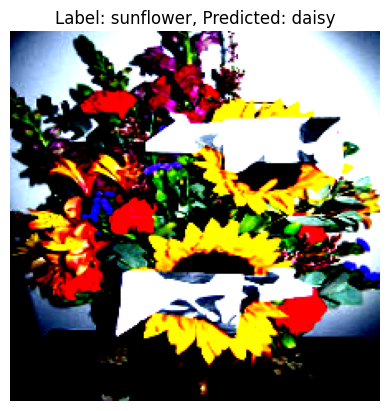

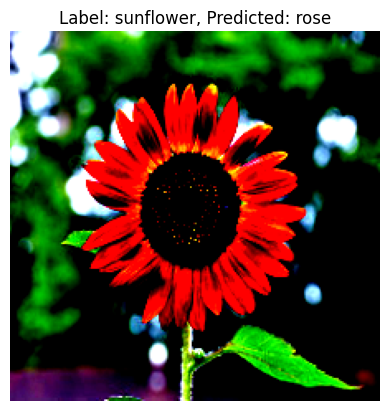

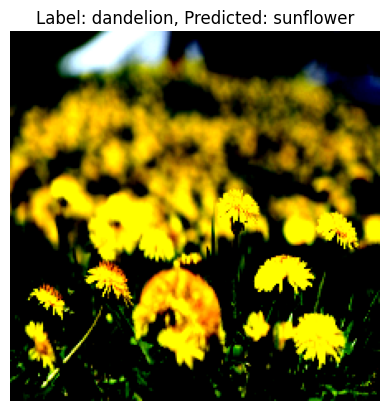

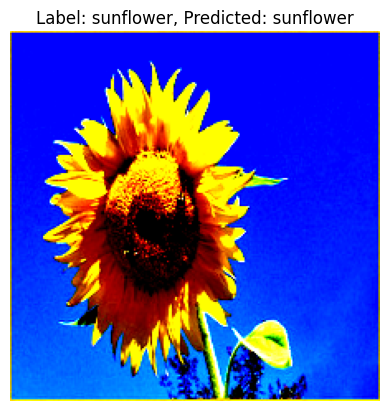

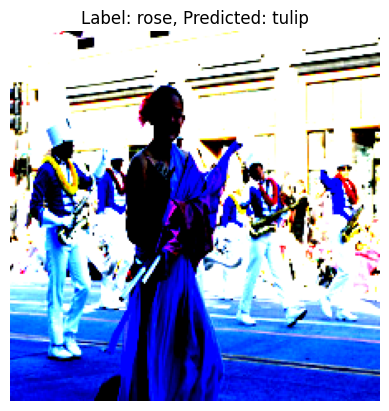

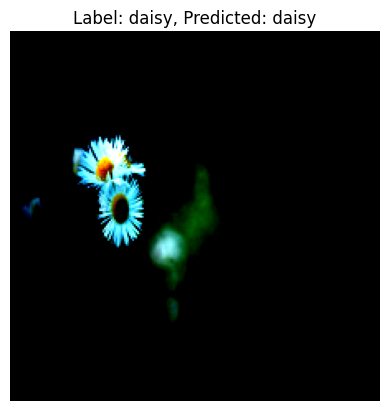

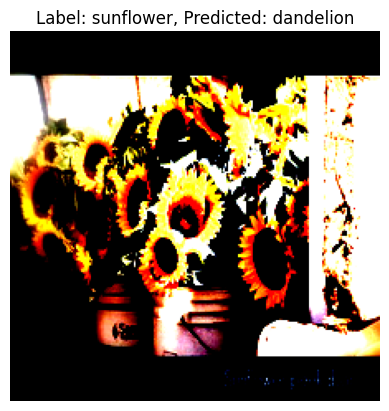

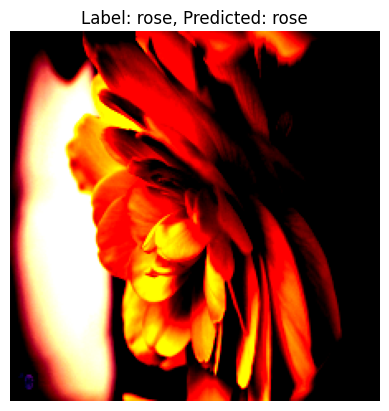

In [14]:
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

def predict_image(img, model):
    # Преобразование to a batch of 1
    xb = img.unsqueeze(0).to(device)
    # Получение прогнозов от модели
    yb = model(xb)
    # Выбираем индекс с наибольшей вероятностью
    _, preds  = torch.max(yb, dim=1)
    # Получение метки класса
    return dataset.classes[preds[0].item()]

for i in range(1,10):
  img, label = val_set[i]
  plt.imshow(img.clip(0,1).permute(1, 2, 0))
  plt.axis('off')
  plt.title('Label: {}, Predicted: {}'.format(dataset.classes[label],predict_image(img, model)))
  plt.show()

# Практическое задание



В задние представлено логика выполнения с использование tensorflow/keras. Выполнять можно как с использованием tensorflow/keras, так и pytorch.

1. Необходимо обучить предобученную сверточную архитектуру для задач классификации цветов.

В выбранной Вами архитектуре также необходимо **разобраться** с основными её параметрами и принципами работы.

Посмотрите как использовать [модели в PyTorch](https://pytorch.org/vision/stable/models.html) для классификации, выберите одну и используя transfer learning до-обучите модель на классификацию цветов. Чтобы это сделать замените ____ в ячейках ниже на работающий код.

2. Реализовать свою архитектуру, также как в разделе "Сверточная нейросеть с нуля".

3. Сравнить три архитектуры (из раздела "Сверточная нейросеть с нуля", предобученую сверточную архитектуру и свою архитектуру (из п. 2)). Визуализировать полученный результат сравнения.





1. Обучение предобученной сверточной архитектуры для задач классификации цветов

Для сравнения
финальных моделей ниже используется отдельная короткая функция оценки:
она считает loss и accuracy на всём validation-наборе после обучения.

In [ ]:
def evaluate_model(model):
    model.eval()
    loss_meter = ValueMeter()
    accuracy_meter = ValueMeter()

    with torch.no_grad():
        for imgs, labels in loaders['validation']:
            imgs = imgs.to(device)
            labels = labels.to(device)
            outputs = model(imgs)
            loss = F.cross_entropy(outputs, labels)
            bs = labels.size(0)
            loss_meter.add(loss.item(), bs)
            accuracy_meter.add(accuracy(outputs, labels), bs)

    return {
        'Loss': loss_meter.value(),
        'Accuracy, %': 100 * float(accuracy_meter.value()),
    }


results = {'Базовая CNN': evaluate_model(model)}
del optimizer  

In [16]:

# Выберите модель из списка доступных в PyTorch моделей
# Не забудьте указать, что она модель должна быть предобучена!
# Написать свой код здесь....
#ResNet-18 с предобученными весами ImageNet
modelResNet = torchvision.models.resnet18(weights='DEFAULT')
modelResNet

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 189MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [17]:
# Функция для заморозки весов модели
def set_parameter_requires_grad(model):
  for param in model.parameters():
    param.requires_grad = False

set_parameter_requires_grad(modelResNet) # передайте модель в функцию для "заморозки" градиента

In [18]:
# Вместо 1000 классов ImageNet нужны 5 классов цветов
modelResNet.fc = nn.Linear(modelResNet.fc.in_features, len(dataset.classes))# Меняем последний слой модели Зачем? Сколькой нужно выходов?

In [19]:
# Проверим все ли сработало правильно, выведем веса, которые будут обучаться
for name, param in modelResNet.named_parameters():
    if param.requires_grad:
        print(name)

fc.weight
fc.bias


In [21]:
modelResNet.to(device) # Отправляем модель на GPU
optimizer = torch.optim.Adam(modelResNet.fc.parameters(), lr=lr) # алгоритм оптимизации
loss_track, accuracy_track = trainval(modelResNet, loaders, optimizer, epochs=10) #обратить внимание на loss_track и accuracy_track
results['ResNet-18'] = evaluate_model(modelResNet)

100%|██████████| 104/104 [00:15<00:00,  6.55it/s]


[training] Epoch: 0.00. Loss: 0.90. Accuracy: 69.16% 


100%|██████████| 32/32 [00:06<00:00,  5.25it/s]


[validation] Epoch: 0.00. Loss: 0.54. Accuracy: 83.50% 


100%|██████████| 104/104 [00:16<00:00,  6.34it/s]


[training] Epoch: 1.00. Loss: 0.70. Accuracy: 76.62% 


... (30 outputs left out)

100%|██████████| 104/104 [00:16<00:00,  6.32it/s]


[training] Epoch: 9.00. Loss: 0.41. Accuracy: 86.07% 


100%|██████████| 32/32 [00:06<00:00,  4.98it/s]

[validation] Epoch: 9.00. Loss: 0.38. Accuracy: 86.66% 


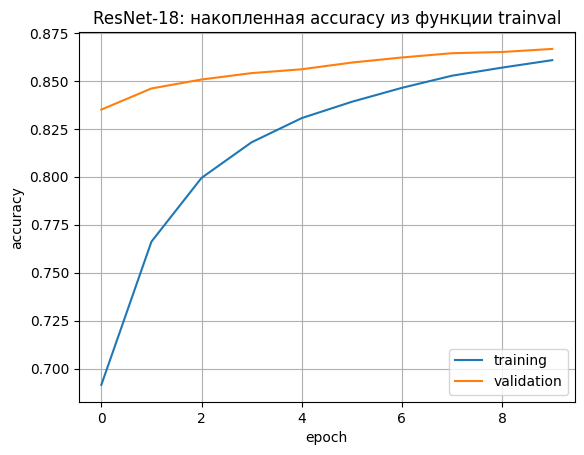

In [22]:
plt.plot(accuracy_track['training'], label='training')
plt.plot(accuracy_track['validation'], label='validation')
plt.title('ResNet-18')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.grid()
plt.legend()
plt.show()

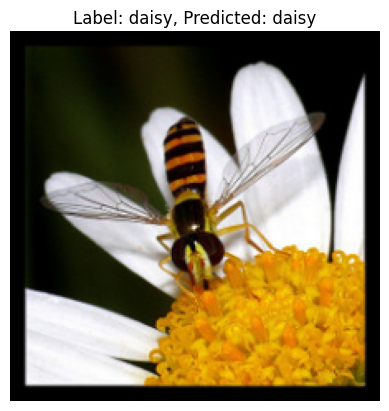

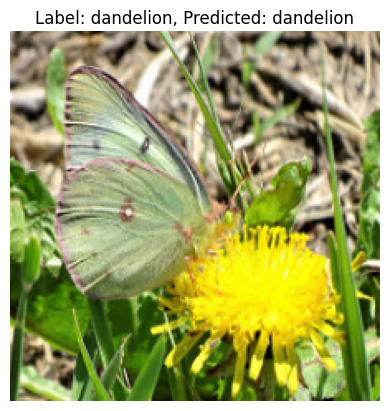

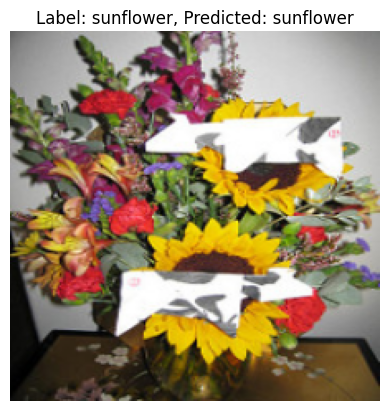

In [27]:
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

def predict_image(img, model):
    xb = img.unsqueeze(0).to(device)
    yb = model(xb)
    _, preds  = torch.max(yb, dim=1)
    return dataset.classes[preds[0].item()]

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


modelResNet.eval()
with torch.no_grad():
    for i in range(3):
        img, label = val_set[i]
        plt.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0))
        plt.axis('off')
        plt.title(f'Label: {dataset.classes[label]}, Predicted: {predict_image(img, modelResNet)}')
        plt.show()

По желанию, можно сохранить веса модели.

In [24]:
weights_fname = '/content/drive/MyDrive/data/resnet18_flowers.pth'
torch.save(modelResNet.state_dict(), weights_fname)

2. Своя архитектура

In [25]:
# Написать свой код здесь
custom_model = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),

    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),

    nn.AdaptiveAvgPool2d((1, 1)),
    nn.Flatten(),
    nn.Linear(128, len(dataset.classes)),
)
custom_model.to(device)
custom_optimizer = torch.optim.Adam(custom_model.parameters(), lr=lr)
custom_loss_track, custom_accuracy_track = trainval(
    custom_model, loaders, custom_optimizer, epochs=10
)
results['Своя CNN'] = evaluate_model(custom_model)





100%|██████████| 104/104 [00:16<00:00,  6.22it/s]


[training] Epoch: 0.00. Loss: 1.31. Accuracy: 41.48% 


100%|██████████| 32/32 [00:04<00:00,  7.24it/s]


[validation] Epoch: 0.00. Loss: 1.24. Accuracy: 46.00% 


100%|██████████| 104/104 [00:16<00:00,  6.23it/s]


[training] Epoch: 1.00. Loss: 1.25. Accuracy: 45.63% 


... (30 outputs left out)

100%|██████████| 104/104 [00:15<00:00,  6.51it/s]


[training] Epoch: 9.00. Loss: 1.07. Accuracy: 57.30% 


100%|██████████| 32/32 [00:04<00:00,  7.67it/s]

[validation] Epoch: 9.00. Loss: 1.04. Accuracy: 57.87% 


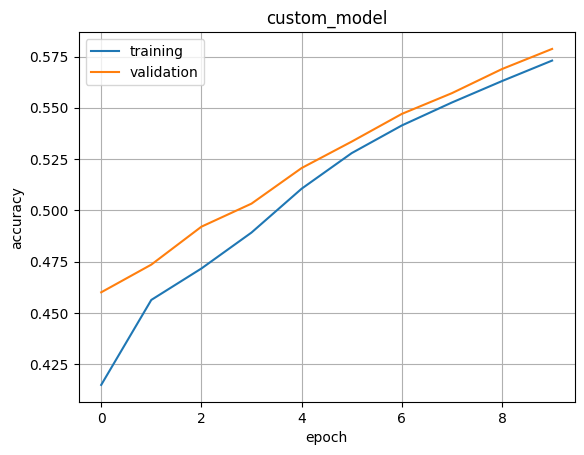

In [28]:
plt.plot(custom_accuracy_track['training'], label='training')
plt.plot(custom_accuracy_track['validation'], label='validation')
plt.title('custom_model')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.grid()
plt.legend()
plt.show()

3. Сравнение и вузуализация 3-х архитектур

              Loss  Accuracy, %
Базовая CNN  2.986         56.6
ResNet-18    0.325         88.1
Своя CNN     0.884         66.7


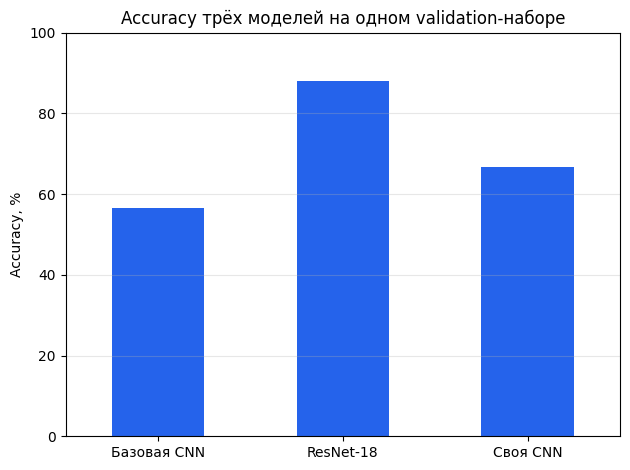

Лучшая модель по validation accuracy: ResNet-18


In [26]:
# Написать свой код здесь


comparison = pd.DataFrame.from_dict(results, orient='index')
print(comparison.round(3))

comparison['Accuracy, %'].plot.bar(color='#2563EB', rot=0)
plt.title('Accuracy трёх моделей на одном validation-наборе')
plt.ylabel('Accuracy, %')
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print('Лучшая модель по validation accuracy:', comparison['Accuracy, %'].idxmax())



## Вопросы.
Добавте описание архитектуры выбранной Вами предобученой сверточной нейронной сети.

**Как работает выбранная вами модель сверточной нейронной сети? Какие параметры?**
Она содержит начальную свёртку, четыре группы остаточных блоков с 64, 128, 256 и
512 каналами, глобальное усреднение и полносвязный классификатор. В остаточном блоке
к результату свёрток прибавляется вход блока: `F(x) + x`; при несовпадении размеров
вход предварительно преобразуется. 

**В чем основные отличия между сверточной нейронной сетью и "обычной" полносвязной нейронной сетью?**

Свёртки работают с локальными участками изображения и используют одни и те же
фильтры во всех позициях. Полносвязный слой связывает каждый выход со всеми входами.
Свёрточные сети учитывают пространственную структуру изображения

**Что такое transfer learning? Что такое предобучена нейронная сеть?**
Предобученная сеть уже получила веса на другом наборе данных.
Transfer learning использует эти признаки для новой задачи. Мы заменяем классификатор
ResNet-18 и обучаем его распознавать пять видов цветов

**Что такое функция для заморозки весов модели?**
Устанавливает `requires_grad=False`, отключая расчёт градиентов для существующих
параметров. Новый слой `fc` создаётся после заморозки и остаётся обучаемым.
В оптимизатор передаются только параметры `model.fc`

**Как работает блок "Сверточная нейросеть с нуля"? Описать сверточный и пулинговый слой.**
Шесть свёрток 3×3 выделяют признаки, ReLU заменяет отрицательные значения нулями,
 MaxPool2d(2, 2) выбирает максимум из окна 2×2 и уменьшает высоту и ширину вдвое.
Для входа 224×224 после трёх pooling-слоёв размер равен 256×28×28.
Flatten разворачивает признаки в вектор, Linear 200704 → 1024 → 512 → 5 выдаёт
оценки пяти классов